# Task 04 — Document retrieval over an ERP estate: where RAG works, and where it stops being a retrieval problem

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [Company Documents Dataset](https://www.kaggle.com/datasets/ayoubcherguelaine/company-documents-dataset): 2,676 PDF invoices, purchase orders, shipping orders and stock reports generated from the classic Northwind trading database
**Task family:** document processing, retrieval (RAG), evaluation · **Companions:** `01` (graphs), `02` (tabular), `03` (text classification)

---

## The task card

> **Board question.** *Finance and operations staff spend hours a week hunting through invoices, shipping orders and stock reports to answer simple questions from customers and auditors. Can a document assistant answer them with a citation, and at what point does it stop being a retrieval problem and become a data-integration one?*

**Business context.** Every mid-sized company has an estate like this: documents produced by an ERP that nobody can query any more because the system that made them was replaced, archived or never exposed. The documents are the *only* durable record. A document assistant (Session 10's production RAG pipeline) is the fast answer; a knowledge layer rebuilt from the documents (Sessions 07–09) is the durable one. This task makes students measure the boundary between the two rather than argue it.

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **document-processing stage** (extraction, classification, field parsing), packaged and tested, with a schema and a quality report;
2. the given **retrieval pipeline** with query understanding, packaged and reproducible, evaluated against a golden set with recall@k and MRR, in CI;
3. the **generation step** with a versioned prompt, citations and a refusal path, evaluated against the golden set (your own LLM access);
4. a one-page **stakeholder recommendation**: which questions the assistant may answer, which must go to the structured path, and what it costs.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | The document estate as a legacy integration problem; where the assistant plugs into finance and ops workflows; access control on documents |
| 2 · MLOps | Extraction as a pipeline stage with tests; retrieval regression in CI; monitoring for template drift |
| 3 · Semantic layer | Entity resolution (truncated product names, customer ids vs names); the Northwind schema as an ontology; Graph-RAG for the questions retrieval cannot answer |
| 4 · LLM/RAG | Chunking, sparse vs dense retrieval, hybrid fusion, query understanding, prompt versioning, judge-based evaluation, cost |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The baseline runs **without any LLM**: it stops at retrieval plus a rule-based reader, which is deliberate: it makes the retrieval quality visible before generation hides it. Five traps are left in, each flagged ⚠ and measured in Section 8; turning each into a test is part of the task.

**Honesty note.** The documents are **synthetic**, generated from Microsoft's Northwind sample database (fictional company, customers, employees and products). Real document estates are messier: scans, mixed templates, handwriting, multiple languages. The method transfers; the extraction difficulty here is a lower bound.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1 | Dataset card | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 2–8 | Extraction and parsing, the golden set, the retrievers, query understanding, the reader, the aggregate question, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 9–12 | The recommendation to write, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 9 is the recommendation your numbers must support; Section 10 sets the targets. |

**What you need from Parts A and B**

- **Code to package:** `get_raw_dir` and `extract_all` (Section 1); `parse_invoice`, `parse_shipping` and `parse_stock` (Section 2); `rrf` and `score` (Section 4); `understand` and `retrieve_with_understanding` (Section 5); `read`, `answer`, `exact_match` and the `generate` stub (Section 6); `grounded`, `reword_date` and `golden_fingerprint` (Section 8).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** 2,676 documents (830 invoices, 830 purchase orders, 809 shipping orders, 207 stock reports); invoice totals found as an exact string in 100 % of the fresh extraction against 0 % of the shipped CSV; 200 golden questions (120 id lookups, 40 paraphrases, 40 stock lookups); with the id/month filter and type routing, recall@1 of 1.00 on id lookups, 0.90 on paraphrases and 1.00 on stock lookups, and exact match 1.00 on id lookups; grounded exact match 0.90 on paraphrases, recall@1 0.20 on the reworded paraphrases, and 0 of 47 aggregate counts right from retrieval (Section 8).
- **Runtime:** under a minute on a laptop (about 25 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
import os, re, time, glob, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pdfplumber
from rank_bm25 import BM25Okapi
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140); pd.set_option("display.max_colwidth", 70)

# ---- parameters -------------------------------------------------------------
SEED = 3217
KAGGLE_HANDLE = "ayoubcherguelaine/company-documents-dataset"
N_GOLD_ORDERS = 40            # orders sampled for the golden set (× 4 question templates)
N_GOLD_STOCK = 40             # stock-report questions
K = 5                         # retrieval depth reported

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
rng = np.random.default_rng(SEED)
T_START = time.time()
import sklearn; print(f"pandas {pd.__version__} · scikit-learn {sklearn.__version__} · pdfplumber {pdfplumber.__version__}")

pandas 3.1.0 · scikit-learn 1.9.1 · pdfplumber 0.11.10


# Part A — Explore the data

*Section 1: read it; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw_dir` and `extract_all`.*

| Field | Value |
|---|---|
| **Source** | Kaggle: `ayoubcherguelaine/company-documents-dataset` (May 2024) |
| **Licence** | Apache-2.0 |
| **Provenance** | Synthetic. PDFs rendered from the Northwind sample database (fictional trading company): 830 orders (ids 10248–11077, Jul 2016 – May 2018), 91 customers, 9 employees, 3 shippers, 77 products in 8 categories |
| **Files** | `CompanyDocuments/invoices/` (830), `PurchaseOrders/` (830), `Shipping orders/` (809), `Inventory Report/monthly/` (23 monthly stock reports) and `Inventory Report/monthly-Category/` (184 per-category reports); plus `company-document-text.csv`, the author's pre-extracted text with a document-type label |
| **Document shapes** | Invoice: order id, customer id, order date, contact and address, product lines, total. Purchase order: order id, date, customer name, product lines. Shipping order (2 pages): ship-to block, customer, employee, shipper, order and shipped dates, product lines with totals, total. Stock report: category / product / units sold / units in stock / unit price for one month |
| **PII** | None real: all people and companies are Northwind fictions. Treat the contact names as if they were real when you design access control (task E4) |

**Known quirks you must handle (and should mention in your write-up):**

1. ⚠ **The pre-extracted CSV is lossy.** Its text is lower-cased, punctuation is stripped and decimals are broken into two tokens (`38 0` for `38.0`), so a numeric question cannot be answered from it. Re-extract from the PDFs. (Trap 1, Section 2.)
2. **Three documents per order.** The invoice, purchase order and shipping order for order 10248 share the id, the customer and the product lines. A retriever that finds "the document about order 10248" has not found *the* document; which one is authoritative depends on the question. (Trap 2, Section 5.)
3. **Two stock reports per month.** The monthly report lists every product; the per-category reports repeat the same rows. The monthly report **truncates long product names** (`Louisiana Fiery Hot..`), so the same product has two surface forms, an entity-resolution problem (Session 08).
4. **Dates are ISO and ids are five-digit integers**, which is kinder than real documents; tokenisers that split numbers, or embeddings that blur them, will still struggle (task E1).
5. **No questions ship with the data.** The golden set below is generated from the parsed fields, which is both its strength (exact ground truth) and its limit (it only asks what the template contains, in the template's words: Trap 4).

In [2]:
def get_raw_dir() -> Path:
    '''Return the local CompanyDocuments directory, downloading the dataset on first use.'''
    local = RAW / "northwind" / "CompanyDocuments"
    if local.exists():
        return local
    import kagglehub
    root = Path(kagglehub.dataset_download(KAGGLE_HANDLE))
    found = list(root.rglob("CompanyDocuments"))
    assert found, "CompanyDocuments folder not found in the download"
    return found[0]

DOC_TYPE_OF_FOLDER = {"invoices": "invoice", "PurchaseOrders": "purchase_order", "Shipping orders": "shipping_order",
                      "Inventory Report": "stock_report"}

def extract_all() -> pd.DataFrame:
    '''Extract text from every PDF with pdfplumber (≈ 1 minute for 2,676 files); cached as parquet.'''
    cache = PROCESSED / "northwind_docs.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    t = time.time()
    base = get_raw_dir()
    rows = []
    for p in sorted(glob.glob(str(base / "**" / "*.pdf"), recursive=True)):
        rel = p.split("CompanyDocuments/")[1]
        with pdfplumber.open(p) as pdf:
            text = "\n".join((pg.extract_text() or "") for pg in pdf.pages)
            n_pages = len(pdf.pages)
        rows.append({"doc_id": Path(p).stem, "path": rel, "doc_type": DOC_TYPE_OF_FOLDER[rel.split("/")[0]],
                     "pages": n_pages, "text": text})
    df = pd.DataFrame(rows)
    df.to_parquet(cache)
    print(f"extracted {len(df):,} PDFs in {time.time()-t:.0f}s")
    return df

docs = extract_all()
print(f"{len(docs):,} documents · {docs.text.str.len().median():.0f} chars median · "
      f"{docs.pages.value_counts().to_dict()} pages")
docs.doc_type.value_counts().to_frame("documents")

2,676 documents · 374 chars median · {1: 1998, 2: 678} pages


,documents
doc_type,
purchase_order,830
invoice,830
shipping_order,809
stock_report,207


# Part B — The given model

*Sections 2–8: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 2 · Document processing is a pipeline stage, not a preprocessing afterthought

*Part B · Given model · package `parse_invoice`, `parse_shipping` and `parse_stock` unchanged; C1 makes extraction a tested stage.*

Session 10 draws the production pipeline as *document processing → chunking → embedding → indexing → retrieval → …*. The first box is where most real RAG projects quietly fail, because a bad extraction is invisible once an LLM has paraphrased it. The dataset ships a pre-extracted text file; compare it with a fresh extraction before trusting either.

**Trap 1 — the lossy CSV.** ⚠ Count how many invoice totals can be found *as an exact string* in each version of the text.

In [3]:
csv_text = pd.read_csv(get_raw_dir().parent / "company-document-text.csv")
print("author's CSV, one invoice:", repr(csv_text.loc[csv_text.label == "invoice", "text"].iloc[0][:160]), "…")
print("fresh PDF extraction, same kind of document:", repr(docs.loc[docs.doc_type == "invoice", "text"].iloc[0][:160]), "…")

inv = docs[docs.doc_type == "invoice"].copy()
inv["total"] = inv.text.str.extract(r"TotalPrice\s+([\d.]+)")[0].astype(float)
inv["order_id"] = inv.text.str.extract(r"Order ID:\s*(\d{5})")[0].astype(int)
csv_blob = " ".join(csv_text.loc[csv_text.label == "invoice", "text"])
pdf_blob = " ".join(inv.text)
raw_totals = inv.text.str.extract(r"TotalPrice\s+([\d.]+)")[0].sample(200, random_state=SEED)   # the figure exactly as printed on the invoice
found_csv = np.mean([t in csv_blob for t in raw_totals])
found_pdf = np.mean([t in pdf_blob for t in raw_totals])
print(f"\ninvoice totals (as printed, e.g. '{raw_totals.iloc[0]}') findable as an exact string · author's CSV: {found_csv:.0%} · fresh extraction: {found_pdf:.0%}")

author's CSV, one invoice: 'invoice order id  10707 customer id  arout order date  2017-10-16 customer details  contact name  thomas hardy address  120 hanover sq. city  london postal code' …
fresh PDF extraction, same kind of document: "Invoice\nOrder ID: 10248\nCustomer ID: VINET\nOrder Date: 2016-07-04\nCustomer Details:\nContact Name: Paul Henriot\nAddress: 59 rue de l'Abbaye\nCity: Reims\nPostal Co" …

invoice totals (as printed, e.g. '1813.0') findable as an exact string · author's CSV: 0% · fresh extraction: 100%


Zero versus one hundred per cent. Any assistant built on the shipped CSV would have answered "what was the total of order 10707?" with confident nonsense. Extraction quality is a *tested* stage from here on (task C1).

### Route by type: a tiny classifier that earns its place

Before retrieving, know what kind of document you are holding. On this estate the four types are trivially separable, which is exactly why the step is cheap insurance: it supplies the metadata that Section 5 shows retrieval cannot do without.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(docs.text, docs.doc_type, test_size=0.3, random_state=SEED, stratify=docs.doc_type)
type_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, sublinear_tf=True)
type_clf = LinearSVC(C=1.0).fit(type_vec.fit_transform(X_train), y_train)
pred = type_clf.predict(type_vec.transform(X_test))
print(f"document-type classifier · held-out accuracy {accuracy_score(y_test, pred):.4f}")
print(classification_report(y_test, pred, digits=3))

document-type classifier · held-out accuracy 1.0000
                precision    recall  f1-score   support

       invoice      1.000     1.000     1.000       249
purchase_order      1.000     1.000     1.000       249
shipping_order      1.000     1.000     1.000       243
  stock_report      1.000     1.000     1.000        62

      accuracy                          1.000       803
     macro avg      1.000     1.000     1.000       803
  weighted avg      1.000     1.000     1.000       803



### Parse the fields: the ERP, recovered from its own paperwork

The templates are regular enough for regular expressions. This is the "structured path": every field parsed here is a column in a table that answers aggregate questions in one line (Section 7). It is also the ground truth for the golden set.

In [5]:
CATEGORIES = ["Beverages", "Condiments", "Confections", "Dairy Products", "Grains/Cereals", "Meat/Poultry", "Produce", "Seafood"]

def parse_invoice(t):
    g = lambda pat: (re.search(pat, t) or [None, None])[1]
    return {"order_id": int(g(r"Order ID:\s*(\d{5})")), "customer_id": g(r"Customer ID:\s*(\w+)"), "order_date": g(r"Order Date:\s*(\S+)"),
            "contact": g(r"Contact Name:\s*(.+)"), "country": g(r"Country:\s*(.+)"), "total": float(g(r"TotalPrice\s+([\d.]+)"))}

def parse_shipping(t):
    g = lambda pat: (re.search(pat, t) or [None, None])[1]
    return {"order_id": int(g(r"Order ID:\s*(\d{5})")), "customer_id": g(r"Customer ID:\s*(\w+)"), "customer_name": g(r"Customer Name:\s*(.+)"),
            "employee": g(r"Employee Name:\s*(.+)"), "shipper": g(r"Shipper Name:\s*(.+)"), "ship_country": g(r"Ship Country:\s*(.+)"),
            "order_date": g(r"Order Date:\s*(\S+)"), "shipped_date": g(r"Shipped Date:\s*(\S+)"), "total": float(g(r"Total Price:\s*([\d.]+)"))}

def parse_stock(t, path):
    month = re.search(r"Stock Report for (\d{4}-\d{2})", t).group(1)
    kind = "monthly" if "/monthly/" in path else "category"
    rows = []
    for line in t.splitlines():
        m = re.match(r"^(.+?)\s+(\d+)\s+(\d+)\s+([\d.]+)$", line)
        if not m or line.startswith(("Product", "Category")):
            continue
        name = m.group(1).strip()
        if kind == "monthly":
            for c in CATEGORIES:
                if name.startswith(c + " "):
                    name = name[len(c) + 1:]; break
        rows.append({"month": month, "report": kind, "product": name, "units_sold": int(m.group(2)),
                     "units_in_stock": int(m.group(3)), "unit_price": float(m.group(4))})
    return rows

t0 = time.time()
invoices = pd.DataFrame([{"doc_id": r.doc_id, **parse_invoice(r.text)} for r in docs[docs.doc_type == "invoice"].itertuples()])
shipping = pd.DataFrame([{"doc_id": r.doc_id, **parse_shipping(r.text)} for r in docs[docs.doc_type == "shipping_order"].itertuples()])
stock = pd.DataFrame([{"doc_id": r.doc_id, **row} for r in docs[docs.doc_type == "stock_report"].itertuples() for row in parse_stock(r.text, r.path)])
docs["order_id"] = docs.text.str.extract(r"Order ID:?\s*(\d{5})")[0].fillna(docs.text.str.extract(r"^(\d{5})\s+\d{4}-\d{2}-\d{2}", flags=re.M)[0]).astype(float)
print(f"parsed {len(invoices)} invoices, {len(shipping)} shipping orders, {len(stock)} stock rows in {time.time()-t0:.1f}s")

# consistency checks a CI stage would run (Session 05): the same facts appear in several documents and must agree
both = invoices.merge(shipping, on="order_id", suffixes=("_inv", "_ship"))
assert np.isclose(both.total_inv, both.total_ship).all(), "invoice and shipping-order totals disagree"
m = stock[stock.report == "monthly"].merge(stock[stock.report == "category"], on=["month", "product"], suffixes=("_m", "_c"))
assert (m.units_in_stock_m == m.units_in_stock_c).all(), "monthly and category stock reports disagree"
truncated = sorted(set(stock.loc[stock.report == "monthly", "product"]) - set(stock.loc[stock.report == "category", "product"]))
print(f"totals agree across {len(both)} orders · stock agrees on {len(m)} product-months · "
      f"{len(truncated)} product names truncated in the monthly report, e.g. {truncated[:3]}")
shipping.head(3)[["doc_id", "order_id", "customer_name", "employee", "shipper", "ship_country", "order_date", "shipped_date", "total"]]

parsed 830 invoices, 809 shipping orders, 2314 stock rows in 0.1s
totals agree across 809 orders · stock agrees on 968 product-months · 13 product names truncated in the monthly report, e.g. ["Chef Anton's Cajun..", "Grandma's Boysenberry..", "Jack's New England.."]


,doc_id,order_id,customer_name,employee,shipper,ship_country,order_date,shipped_date,total
0,order_10248,10248,Vins et alcools Chevalier,Steven Buchanan,Federal Shipping,France,2016-07-04,2016-07-16,440.0
1,order_10249,10249,Toms Spezialitäten,Michael Suyama,Speedy Express,Germany,2016-07-05,2016-07-10,1863.4
2,order_10250,10250,Hanari Carnes,Margaret Peacock,United Package,Brazil,2016-07-08,2016-07-12,1813.0


## 3 · A golden set with exact ground truth

*Part B · Given model · regenerate the golden set exactly; C4 gates on it.*

Session 10 insists on a golden set before any retrieval decision. Here it can be *generated*: every question is built from a parsed field, so the relevant document(s) and the answer are known exactly. Three families, by increasing difficulty for a retriever:

- **ID lookups**: "What was the total price of order 10973?" The id is in the question; the difficulty is *which* of the three documents.
- **Paraphrased lookups**: "Which shipping company delivered the order placed on 2017-06-12 by Ernst Handel?" No id; the retriever has to match a name and a date.
- **Stock lookups**: "How many units of Chang were in stock in 2016-07?" Two relevant documents (monthly and category report), one of which may carry a truncated name.

Plus a fourth family in Section 7 that retrieval is not meant to answer.

In [6]:
gold = []
order_ids = rng.choice(shipping.order_id.values, N_GOLD_ORDERS, replace=False)
for oid in order_ids:
    i = invoices[invoices.order_id == oid].iloc[0]; s = shipping[shipping.order_id == oid].iloc[0]
    gold += [
        {"family": "id lookup", "question": f"What was the total price of order {oid}?", "relevant": {i.doc_id, s.doc_id}, "answer": f"{i.total:g}", "field": "total"},
        {"family": "id lookup", "question": f"Who is the contact name on the invoice for order {oid}?", "relevant": {i.doc_id}, "answer": i.contact, "field": "contact"},
        {"family": "id lookup", "question": f"Which shipper delivered order {oid}?", "relevant": {s.doc_id}, "answer": s.shipper, "field": "shipper"},
        {"family": "paraphrase", "question": f"Which shipping company delivered the order placed on {s.order_date} by {s.customer_name}?", "relevant": {s.doc_id}, "answer": s.shipper, "field": "shipper"},
    ]
for r in stock[stock.report == "category"].sample(N_GOLD_STOCK, random_state=SEED).itertuples():
    rel = set(stock[(stock.month == r.month) & (stock["product"] == r.product)].doc_id)
    gold.append({"family": "stock lookup", "question": f"How many units of {r.product} were in stock in {r.month}?", "relevant": rel,
                 "answer": str(r.units_in_stock), "field": "units_in_stock"})
gold = pd.DataFrame(gold)
print(f"{len(gold)} questions · {gold.family.value_counts().to_dict()} · relevant docs per question: {gold.relevant.map(len).describe()[['min','mean','max']].round(2).to_dict()}")
gold.sample(5, random_state=1)[["family", "question", "answer"]]

200 questions · {'id lookup': 120, 'paraphrase': 40, 'stock lookup': 40} · relevant docs per question: {'min': 1.0, 'mean': 1.35, 'max': 2.0}


,family,question,answer
58,id lookup,Which shipper delivered order 10664?,Federal Shipping
40,id lookup,What was the total price of order 10750?,1871.25
34,id lookup,Which shipper delivered order 10542?,Federal Shipping
102,id lookup,Which shipper delivered order 10804?,United Package
184,stock lookup,How many units of Thüringer Rostbratwurst were in stock in 2018-02?,0


## 4 · Retrieval: four retrievers, one scoreboard

*Part B · Given model · package `score` and `rrf`; the scoreboard becomes C4's CI gate.*

Documents here are one or two pages, so the unit of retrieval is the document and no chunking is needed. Each retriever returns a ranked list; the scoreboard reports **recall@1**, **recall@5** and **MRR** per question family: the numbers a CI gate will later protect.

In [7]:
STOP = set("what was the of on in for by is a an which who when how many were to and did".split())
tok_raw = lambda s: re.findall(r"[\w\.-]+", s.lower())
tok = lambda s: [w for w in tok_raw(s) if w not in STOP]

corpus = docs.text.tolist(); doc_ids = docs.doc_id.values; doc_types = docs.doc_type.values; doc_orders = docs.order_id.values
bm25_raw = BM25Okapi([tok_raw(t) for t in corpus])
bm25 = BM25Okapi([tok(t) for t in corpus])
tfidf = TfidfVectorizer(token_pattern=r"[\w\.-]+", sublinear_tf=True, stop_words=list(STOP)).fit(corpus)
M = tfidf.transform(corpus)

def rrf(*rankings, k=60):
    s = {}
    for ranking in rankings:
        for rank, i in enumerate(ranking[:50], start=1):
            s[i] = s.get(i, 0) + 1 / (k + rank)
    return np.array(sorted(s, key=s.get, reverse=True))

RETRIEVERS = {
    "BM25, raw tokens":        lambda q: np.argsort(-bm25_raw.get_scores(tok_raw(q))),
    "BM25, stop-words removed": lambda q: np.argsort(-bm25.get_scores(tok(q))),
    "TF-IDF cosine":           lambda q: np.argsort(-(M @ tfidf.transform([q]).T).toarray().ravel()),
    "hybrid (RRF of BM25 + TF-IDF)": lambda q: rrf(np.argsort(-bm25.get_scores(tok(q))), np.argsort(-(M @ tfidf.transform([q]).T).toarray().ravel())),
}

def score(retriever, questions=gold, k=K):
    rows = []
    for g in questions.itertuples():
        top = [doc_ids[i] for i in retriever(g.question)[:k]]
        hits = [d in g.relevant for d in top]
        rows.append({"family": g.family, "recall@1": hits[0], f"recall@{k}": any(hits),
                     "MRR": next((1 / (r + 1) for r, h in enumerate(hits) if h), 0.0)})
    return pd.DataFrame(rows).groupby("family").mean()

t0 = time.time()
board = pd.concat({name: score(fn) for name, fn in RETRIEVERS.items()}, names=["retriever", "family"])
print(f"scored {len(RETRIEVERS)} retrievers × {len(gold)} questions in {time.time()-t0:.0f}s")
board.unstack("family").style.format("{:.2f}").background_gradient(cmap="Blues", axis=None, vmin=0, vmax=1)

scored 4 retrievers × 200 questions in 4s


Two things jump out. The paraphrased questions are *easy*: a customer name plus a date is as distinctive as a key. The id lookups are *hard* despite containing a unique five-digit id, and the raw-token BM25 is close to useless on them. The reason is mundane and worth dissecting with students: "total", "price" and "order" appear in hundreds of documents and, under this BM25 implementation's handling of very common terms, together they outweigh the single rare id; stop-word removal helps, but what the question actually contains is a *key*, and keys want a lookup, not a similarity search.

## 5 · Query understanding: the step that turns a key into a filter

*Part B · Given model · package `understand` and `retrieve_with_understanding` unchanged; C3 tests them and Trap 2.*

Session 09 calls it query understanding; Session 10 calls it metadata filtering. Here it is twenty lines: extract an order id or a month from the question and restrict the candidates; detect the document type the question implies and route to it. **Trap 2 ⚠** is why the second half matters: three documents share each order id, and only one of them is the right answer to "who is the contact name" (the invoice) or "which shipper" (the shipping order).

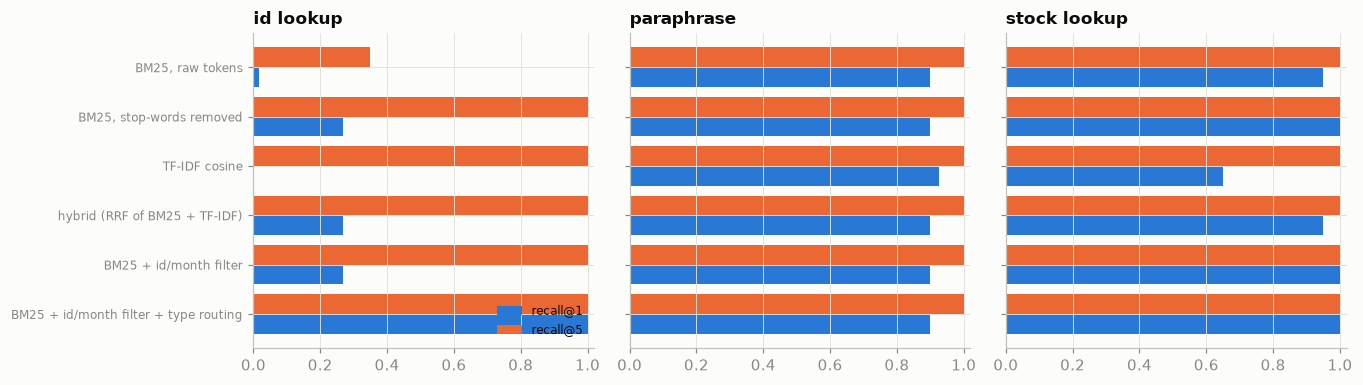

In [8]:
def understand(q):
    '''Return (order_id or None, month or None, implied doc_type or None).'''
    oid = re.search(r"\b(1\d{4})\b", q); month = re.search(r"\b(20\d{2}-\d{2})(?!-\d)", q)   # a month, not a full date
    ql = q.lower()
    if any(w in ql for w in ("invoice", "contact", "address", "billed", "total")): dtype = "invoice"   # the invoice is authoritative for totals: a business rule
    elif any(w in ql for w in ("ship", "deliver", "carrier", "employee")): dtype = "shipping_order"
    elif any(w in ql for w in ("stock", "units", "sold")): dtype = "stock_report"
    elif "purchase" in ql: dtype = "purchase_order"
    else: dtype = None
    return (int(oid.group(1)) if oid else None, month.group(1) if month else None, dtype)

def retrieve_with_understanding(q, use_type=True):
    scores = bm25.get_scores(tok(q)).astype(float)
    oid, month, dtype = understand(q)
    if oid is not None:
        scores = np.where(doc_orders == oid, scores + 1000, scores)          # hard filter, expressed as a boost
    if month is not None:
        scores = np.where(np.char.find(np.array(corpus, dtype=str), f"Stock Report for {month}") >= 0, scores + 1000, scores)
    if use_type and dtype is not None:
        scores = np.where(doc_types == dtype, scores + 500, scores)
    return np.argsort(-scores)

RETRIEVERS["BM25 + id/month filter"] = lambda q: retrieve_with_understanding(q, use_type=False)
RETRIEVERS["BM25 + id/month filter + type routing"] = lambda q: retrieve_with_understanding(q, use_type=True)
board = pd.concat({name: score(fn) for name, fn in RETRIEVERS.items()}, names=["retriever", "family"])

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6), sharey=True)
for ax, fam in zip(axes, ["id lookup", "paraphrase", "stock lookup"]):
    sub = board.xs(fam, level="family")
    y = np.arange(len(sub))
    ax.barh(y + 0.2, sub["recall@1"], height=0.4, color=SERIES[0], label="recall@1")
    ax.barh(y - 0.2, sub[f"recall@{K}"], height=0.4, color=SERIES[1], label=f"recall@{K}")
    ax.set_yticks(y); ax.set_yticklabels(sub.index, fontsize=8); ax.invert_yaxis(); ax.set_xlim(0, 1.02)
    ax.set_title(fam)
axes[0].legend(fontsize=8, loc="lower right")
plt.tight_layout()
board.unstack("family").style.format("{:.2f}").background_gradient(cmap="Blues", axis=None, vmin=0, vmax=1)

With the filter, recall@5 on id lookups reaches 100 % (all three documents are in the top five); with type routing, recall@1 follows. Nothing was learned; the pipeline simply stopped asking a similarity engine to do a lookup's job. The stock questions are capped by the truncated product names: the monthly report cannot be matched by name for a slice of products, which is the entity-resolution task (E2).

## 6 · Answering: a reader that proves where the difficulty lives

*Part B · Given model · package `read`, `answer` and `exact_match`; C5 replaces the `generate` stub with a governed LLM call.*

The baseline has no LLM on purpose. A rule-based **reader** pulls the asked-for field out of the top document; if the retriever found the right document, the reader is right. Measuring exact-match answer accuracy against retrieval recall separates the two failure modes, the first thing a Session 11 evaluation should do, and the last thing most teams do.

In [9]:
FIELD_PATTERNS = {"total": r"(?:TotalPrice|Total Price:)\s*([\d.]+)", "contact": r"Contact Name:\s*(.+)", "shipper": r"Shipper Name:\s*(.+)"}

def read(question, field, doc_text):
    if field == "units_in_stock":
        prod = re.search(r"units of (.+?) were in stock", question).group(1)
        for line in doc_text.splitlines():
            m = re.match(r"^(.+?)\s+(\d+)\s+(\d+)\s+([\d.]+)$", line)
            if m and m.group(1).strip().endswith(prod):
                return m.group(3)
        return None
    m = re.search(FIELD_PATTERNS[field], doc_text)
    return (f"{float(m.group(1)):g}" if field == "total" else m.group(1).strip()) if m else None

def answer(question, field, retriever, k=1):
    '''Retrieve, read the top document, return (answer, citation). A None answer is a refusal — the honest outcome when the field is absent.'''
    top = retriever(question)[:k]
    for i in top:
        a = read(question, field, corpus[i])
        if a is not None:
            return a, doc_ids[i]
    return None, doc_ids[top[0]]

def exact_match(retriever_name):
    fn = RETRIEVERS[retriever_name]
    rows = []
    for g in gold.itertuples():
        a, cite = answer(g.question, g.field, fn, k=1)
        rows.append({"family": g.family, "exact match": (a == g.answer), "refused": a is None, "cited a relevant doc": cite in g.relevant})
    return pd.DataFrame(rows).groupby("family").mean()

em = pd.concat({n: exact_match(n) for n in ["BM25, stop-words removed", "BM25 + id/month filter + type routing"]}, names=["retriever", "family"])
em.style.format("{:.2f}")

In [10]:
# What a generation step would receive. Students replace `generate` with a real LLM call behind a versioned prompt (task C5).
PROMPT_VERSION = 1
def generate(question, passages, prompt_version=PROMPT_VERSION):
    '''Stub: returns the context assembled for an LLM. Replace with a call to your model; keep the signature and the citation contract.'''
    context = "\n\n".join(f"[{d}]\n{t[:600]}" for d, t in passages)
    return {"prompt_version": prompt_version, "question": question, "context_chars": len(context), "citations": [d for d, _ in passages],
            "instruction": "Answer only from the context. Cite the document id for every claim. If the context does not contain the answer, say so."}

q = gold.iloc[0].question
top = retrieve_with_understanding(q)[:3]
print(json.dumps(generate(q, [(doc_ids[i], corpus[i]) for i in top]), indent=2)[:700], "…")

{
  "prompt_version": 1,
  "question": "What was the total price of order 10973?",
  "context_chars": 1324,
  "citations": [
    "invoice_10973",
    "purchase_orders_10973",
    "order_10973"
  ],
  "instruction": "Answer only from the context. Cite the document id for every claim. If the context does not contain the answer, say so."
} …


Exact-match accuracy tracks retrieval recall@1 almost one-to-one (Trap 3 shows where it does not). On an estate like this the generation step adds fluency, not correctness; what it *can* add is harm, if it answers from the wrong document in the right tone. That is the argument for the citation contract in the stub above, and for the refusal path.

## 7 · Where retrieval stops: the aggregate question

*Part B · Given model · read; the structured-path argument your recommendation must make.*

> *How many orders did Federal Shipping deliver to Germany in 2017?*

Every shipping order to Germany in 2017 is "relevant", so recall@5 cannot be reached by design, and no amount of reranking helps; a generator fed the top five would confidently count to five. The parsed table from Section 2 answers in one line. Trap 5 measures what the lookup metric says about these questions. This is Session 09's *evidence question* in miniature: measure when the structured or graph path earns its cost instead of assuming it.

In [11]:
shipping["year"] = shipping.shipped_date.str[:4]
agg_questions = []
for (shp, ctry, yr), n in shipping.groupby(["shipper", "ship_country", "year"]).size().items():
    if n >= 6:
        agg_questions.append({"question": f"How many orders did {shp} deliver to {ctry} in {yr}?", "answer": int(n),
                              "relevant": set(shipping[(shipping.shipper == shp) & (shipping.ship_country == ctry) & (shipping.year == yr)].doc_id)})
agg = pd.DataFrame(agg_questions).sample(min(10, len(agg_questions)), random_state=SEED)

rows = []
for g in agg.itertuples():
    top = [doc_ids[i] for i in retrieve_with_understanding(g.question)[:K]]
    rows.append({"question": g.question, "relevant docs": len(g.relevant), f"relevant in top-{K}": sum(d in g.relevant for d in top),
                 "answer via retrieval@5": sum(d in g.relevant for d in top), "answer via parsed table": g.answer})
pd.DataFrame(rows).style.format({"answer via retrieval@5": "{:d}", "answer via parsed table": "{:d}"})

,question,relevant docs,relevant in top-5,answer via retrieval@5,answer via parsed table
0,How many orders did Speedy Express deliver to France in 2018?,6,0,0,6
1,How many orders did Speedy Express deliver to USA in 2018?,8,1,1,8
2,How many orders did Federal Shipping deliver to Brazil in 2017?,9,4,4,9
3,How many orders did Federal Shipping deliver to Mexico in 2016?,7,3,3,7
4,How many orders did Speedy Express deliver to Spain in 2018?,6,3,3,6
5,How many orders did Speedy Express deliver to France in 2016?,7,1,1,7
6,How many orders did Speedy Express deliver to USA in 2017?,19,2,2,19
7,How many orders did United Package deliver to France in 2017?,14,0,0,14
8,How many orders did United Package deliver to Sweden in 2018?,6,2,2,6
9,How many orders did Federal Shipping deliver to France in 2017?,10,3,3,10


## 8 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test.*

Five shortcuts, each giving a better number and a worse system. Traps 1–2 were measured where they arose; Traps 3–5 are measured here, on the full pipeline (filter plus type routing).

**Trap 1 — the lossy CSV** (Section 2). The shipped text holds 0 % of the invoice totals as printed; a fresh extraction holds 100 %.

**Trap 2 — the right order, the wrong document** (Section 5). With the id filter alone, recall@5 on id lookups is 1.00 (all three documents of the order are in the top five), but recall@1, the document the reader reads, is 0.27; type routing lifts it to 1.00. A gate on recall@5 would pass the broken version.

**Trap 3 — the right answer from the wrong document.** Exact match checks the string, not its source. A shipper question has three possible answers, so a reader of the wrong order is often right by luck. Count an answer only when its citation is relevant.

In [12]:
best = RETRIEVERS["BM25 + id/month filter + type routing"]

def grounded(retriever, questions=gold):
    '''Exact match, and exact match that also cites a relevant document, per question family.'''
    rows = []
    for g in questions.itertuples():
        a, cite = answer(g.question, g.field, retriever, k=1)
        rows.append({"family": g.family, "exact match": a == g.answer, "grounded exact match": (a == g.answer) and (cite in g.relevant)})
    return pd.DataFrame(rows).groupby("family").mean()

trap3 = grounded(best)
display(trap3.style.format("{:.2f}"))

par = gold[gold.family == "paraphrase"]
ship_by_doc = shipping.set_index("doc_id")
same_key = [((shipping.customer_name == ship_by_doc.loc[next(iter(g.relevant)), "customer_name"]) &
             (shipping.order_date == ship_by_doc.loc[next(iter(g.relevant)), "order_date"])).sum() for g in par.itertuples()]
modal = shipping.shipper.value_counts()
print(f"paraphrase questions whose customer placed more than one order that day (a second right document the golden set omits): {sum(n > 1 for n in same_key)} of {len(par)}")
print(f"always answering '{modal.index[0]}' gets {(gold.loc[gold.field == 'shipper', 'answer'] == modal.index[0]).mean():.0%} of the "
      f"{(gold.field == 'shipper').sum()} shipper questions right without reading anything")

,exact match,grounded exact match
family,,
id lookup,1.00,1.00
paraphrase,1.00,0.90
stock lookup,1.00,1.00


paraphrase questions whose customer placed more than one order that day (a second right document the golden set omits): 2 of 40
always answering 'United Package' gets 40% of the 80 shipper questions right without reading anything


Exact match is 1.00 on every family; grounded, the paraphrases fall to 0.90. In the four misses the retriever picked another order by the same customer and the shipper happened to match. Two of the 40 questions (one a miss) name a customer with two orders that day: a second right document the golden set does not list. A constant guess already scores 40 % on shipper questions. Gate on grounded exact match, and list every correct document.

**Trap 4 — the golden set speaks the template's language.** Every paraphrase copies the customer name and ISO date exactly as the shipping order prints them, so it rewards matching the template. Ask the same 40 questions as a clerk would write them.

In [13]:
import unicodedata

def reword_date(q):
    '''2017-06-12 -> 12 June 2017: the same question, written as a person would.'''
    d = re.search(r"(\d{4})-(\d{2})-(\d{2})", q)
    dt = pd.Timestamp(d.group(0))
    return q.replace(d.group(0), f"{dt.day} {dt.strftime('%B %Y')}")

def plain_name(q):
    '''Lower-case the customer name and drop its accents.'''
    return re.sub(r"by (.+)\?$", lambda m: "by " + unicodedata.normalize("NFKD", m.group(1)).encode("ascii", "ignore").decode().lower() + "?", q)

variants = {"as generated from the template": par.question, "name lower-cased, accents dropped": par.question.map(plain_name),
            "date written as '12 June 2017'": par.question.map(reword_date)}
trap4 = pd.concat({k: score(best, par.assign(question=v)) for k, v in variants.items()}, names=["paraphrase questions", "family"]).droplevel("family")
print("e.g.", variants["date written as '12 June 2017'"].iloc[0])
display(trap4.style.format("{:.2f}"))
print(f"pooled recall@1 over all {len(gold)} golden questions, as a dashboard would show it: "
      f"{(score(best)['recall@1'] * gold.family.value_counts()).sum() / len(gold):.2f} · "
      f"orders per customer (median): {shipping.customer_name.value_counts().median():.0f}")

e.g. Which shipping company delivered the order placed on 24 March 2018 by La corne d'abondance?


,recall@1,recall@5,MRR
paraphrase questions,,,
as generated from the template,0.90,1.00,0.95
"name lower-cased, accents dropped",0.88,1.00,0.94
date written as '12 June 2017',0.20,0.62,0.33


pooled recall@1 over all 200 golden questions, as a dashboard would show it: 0.98 · orders per customer (median): 8


The name barely matters (BM25 lower-cases anyway); the date is everything. Written out, it drops recall@1 from 0.90 to 0.20 and recall@5 from 1.00 to 0.62 (25 of 40): the ISO date was acting as a key, and a customer alone matches a median of eight orders. The pooled recall@1 a dashboard would show is 0.98, carried by 120 id lookups the filter makes trivial. Report per family, and version a reworded family into the golden set (E1 extends it).

**Trap 5 — recall@k on a question retrieval cannot answer.** Score Section 7's aggregate questions as the scoreboard scores lookups (a hit if any relevant document is in the top five), then check the count.

In [14]:
rows5 = []
for g in pd.DataFrame(agg_questions).itertuples():
    top = [doc_ids[i] for i in best(g.question)[:K]]
    hits = sum(d in g.relevant for d in top)
    rows5.append({"any relevant in top 5": hits > 0, "share of relevant docs in top 5": hits / len(g.relevant), "count correct": hits == g.answer})
trap5 = pd.DataFrame(rows5)
print(f"{len(trap5)} aggregate questions (shipper × country × year, at least six orders each)")
display(trap5.mean().to_frame("mean").T.style.format("{:.2f}"))

47 aggregate questions (shipper × country × year, at least six orders each)


,any relevant in top 5,share of relevant docs in top 5,count correct
mean,0.85,0.24,0.00


By the lookup metric retrieval "works" on 85 % of the aggregate questions; it holds a quarter of the documents it needs, and the count is right for none of the 47. Recall@k is the wrong metric for this class: route these questions to the structured path and test its answer.

Side by side, the number each shortcut reports against the number the system earns:

,naive metric,naive,honest metric,honest
trap,,,,
Trap 2 · id lookups,"recall@5, id filter only",1.00,"recall@1, id filter only",0.27
Trap 3 · paraphrases,exact match,1.00,grounded exact match,0.90
Trap 4 · paraphrases,"recall@1, template wording",0.90,"recall@1, date as people write it",0.20
Trap 5 · aggregates,any relevant in top 5,0.85,count correct,0.00


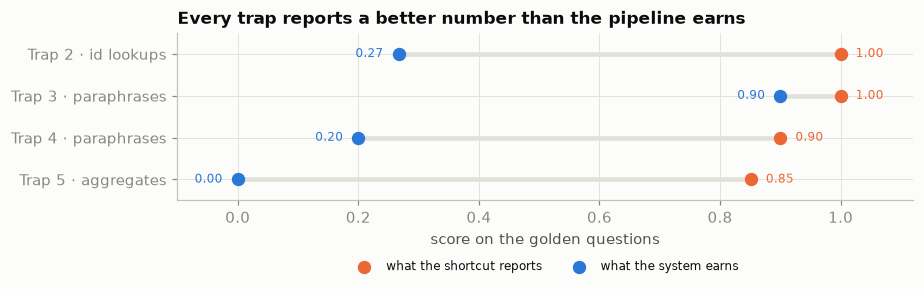

golden set SHA-256 92e859abed6109c9… · 200 questions · index: 2,676 documents, TF-IDF vocabulary 4,287 terms · questions where understand() finds an id or month: 80%


In [15]:
traps = pd.DataFrame([
    ("Trap 2 · id lookups", "recall@5, id filter only", board.loc[("BM25 + id/month filter", "id lookup"), f"recall@{K}"],
     "recall@1, id filter only", board.loc[("BM25 + id/month filter", "id lookup"), "recall@1"]),
    ("Trap 3 · paraphrases", "exact match", trap3.loc["paraphrase", "exact match"], "grounded exact match", trap3.loc["paraphrase", "grounded exact match"]),
    ("Trap 4 · paraphrases", "recall@1, template wording", trap4.loc["as generated from the template", "recall@1"],
     "recall@1, date as people write it", trap4.loc["date written as '12 June 2017'", "recall@1"]),
    ("Trap 5 · aggregates", "any relevant in top 5", trap5["any relevant in top 5"].mean(), "count correct", trap5["count correct"].mean()),
], columns=["trap", "naive metric", "naive", "honest metric", "honest"]).set_index("trap")
display(traps.style.format({"naive": "{:.2f}", "honest": "{:.2f}"}))

fig, ax = plt.subplots(figsize=(8.5, 3.2))
y = np.arange(len(traps))
ax.hlines(y, traps.honest, traps.naive, color=GRID, lw=3, zorder=1)
ax.scatter(traps.naive, y, color=SERIES[1], s=60, zorder=2, label="what the shortcut reports")
ax.scatter(traps.honest, y, color=SERIES[0], s=60, zorder=3, label="what the system earns")
for yi, (n, h) in enumerate(zip(traps.naive, traps.honest)):
    ax.text(n + 0.025, yi, f"{n:.2f}", color=SERIES[1], fontsize=8, va="center")
    ax.text(h - 0.025, yi, f"{h:.2f}", color=SERIES[0], fontsize=8, va="center", ha="right")
ax.set_yticks(y); ax.set_yticklabels(traps.index); ax.set_ylim(len(traps) - 0.5, -0.5); ax.set_xlim(-0.1, 1.12)
ax.set_title("Every trap reports a better number than the pipeline earns"); ax.set_xlabel("score on the golden questions")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.5), ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

def golden_fingerprint(questions=gold):
    '''SHA-256 of the golden set (question, answer, sorted relevant ids): the frozen artefact the CI gate checks.'''
    import hashlib
    recs = [[g.question, g.answer, sorted(g.relevant)] for g in questions.itertuples()]
    return hashlib.sha256(json.dumps(recs, ensure_ascii=False).encode()).hexdigest()

keyed = np.mean([any(x is not None for x in understand(q)[:2]) for q in gold.question])
print(f"golden set SHA-256 {golden_fingerprint()[:16]}… · {len(gold)} questions · "
      f"index: {len(docs):,} documents, TF-IDF vocabulary {len(tfidf.vocabulary_):,} terms · "
      f"questions where understand() finds an id or month: {keyed:.0%}")

# Part C — Productionise it

*Sections 9–12: this is your assignment.*

## 9 · Reading the result — the recommendation to write

*Part C · Productionise · the recommendation you will write, with this notebook's numbers.*

1. **Extraction is the first quality gate.** The shipped text would have made every numeric answer wrong; a tested extraction stage with field-level checks (totals agree across documents) is cheap and catches it.
2. **Lookups want keys, not similarity.** The single biggest improvement came from twenty lines of query understanding, not from a better model. Dense embeddings tend to make id lookups *worse*, one reason the pipeline you are given does not use them.
3. **One estate, three question classes, two architectures.** Lookups: retrieval plus a reader or an LLM with citations. Aggregates and joins: the structured table or, once the entity-resolution problems multiply, a knowledge graph (Session 08) queried by Graph-RAG (Session 09). The recommendation names which questions go where and what each path costs to maintain.
4. **Evaluation is cheap here and should be in CI.** The golden set is generated, so retrieval recall is a regression test that runs on every change to chunking, tokenisation or the index (Session 10's prompt and retrieval labs).

## 10 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The ten principles every project covers, updated with what this notebook measured.

| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/erp_rag/` (`extract.py`: pdfplumber and the three parsers; `retrieve.py`: BM25, `understand`, type routing; `read.py`: the reader and the `generate` stub); `POST /ask` returning answer, citation or refusal; compose with the parsed tables in DuckDB or Postgres for the structured path |
| Monitoring (S04) | Refusal rate (0.00 on the golden set); share of questions where `understand()` finds an id or month (80 % of the golden set; a fall means people stopped asking with keys); parse failures per document type (none among 830 invoices and 809 shipping orders); type classifier against the folder (held-out accuracy 1.0000); latency |
| CI/CD gate (S05) | 200 golden questions, SHA-256 `92e859abed6109c9…`: recall@1 and grounded exact match per family, today 1.00 / 0.90 / 1.00 (id, paraphrase, stock); fail on a drop of more than 0.05 in any family; the reworded paraphrases (recall@1 0.20) gated against falling further; extraction tests (totals agree across 809 orders, stock across 968 product-months, the shipped CSV refused) |
| MLflow tracking and registry (S06) | Tokeniser and stop-word list, the boosts (+1000 id/month, +500 type), `K`, `PROMPT_VERSION`, the golden-set fingerprint, the scoreboard per family and the trap table; `champion` alias on index plus prompt |
| Offline / online training and serving | Index built offline in batch as documents arrive (2,676 documents, TF-IDF vocabulary 4,287 terms; extraction about a minute); questions answered online; aggregate questions routed to the parsed tables, not the index |
| Data and model drift | Template drift (S3): a moved field breaks the regex parsers and the reader silently, seen first as parse failures and refusals. Query drift: dates written out drop paraphrase recall@1 from 0.90 to 0.20 (Trap 4), seen as a falling keyed-question share |
| Knowledge base and context (S07–S09) | Parsed tables as the structured path (830 invoices, 809 shipping orders, 2,314 stock rows); 13 truncated product names to resolve (E2); the Northwind schema as an ontology and graph (S1). On the 47 aggregate questions retrieval scores 0.85 any-hit recall@5 and 0.00 correct counts; the table answers all of them |
| GenAI and context engineering (S10–S11) | Generation from the top three documents only, behind a versioned prompt with a citation contract and a refusal path (C5); judge calibrated against grounded exact match, not plain exact match (S2, Trap 3) |
| Governance | Synthetic, Apache-2.0; contact names and addresses treated as personal data: document-level permissions, audit log, retention (E4); the shipped CSV is not used |

## 11 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S2**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap, with a test.** Turn each trap in Section 8 into a test that fails the pipeline: an extraction test that refuses the shipped CSV and checks the cross-document totals and stock (Trap 1); a routing test that the top document for each id question is of the authoritative type (Trap 2); grounded exact match in place of exact match, with every correct document listed for ambiguous golden questions (Trap 3); a reworded paraphrase family in the golden set (Trap 4); and a test that aggregate questions go to the structured path instead of being scored by recall@k (Trap 5). Move extraction and parsing into `src/` with a schema per document type (pandera, Session 05) and a quality report written on every run.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Query understanding as code.** Turn `understand()` into a tested module (ids, months, date ranges, customer names via the parsed customer table, document type), and show its marginal effect on each question family. Record the decision to filter rather than rerank as an ADR.
- **C4 — Package, container, retrieval regression in CI.** `src/erp_rag/` behind `POST /ask` in a container; the scoreboard becomes a `make retrieval-test` target that checks the golden set's fingerprint and gates on recall@1 and grounded exact match per family (Section 10), the reworded family included; a change that drops any family below the gate blocks the merge (Sessions 02, 03, 05).
- **C5 — The generation step, governed.** Replace the stub with a real LLM call (a local model, or a free hosted tier, per `docs/llm-access.md`) behind a versioned prompt file with a citation contract and a refusal instruction; extend the golden set with questions the template cannot answer ("what was the discount on order 10248?"), which must be refused, and questions with a date range, and version it; evaluate exact match, citation correctness and refusal precision; add the prompt regression suite to CI (Session 10).

### Extension

- **E1 — Questions as people ask them.** Rewrite 40 golden questions the way a finance clerk would ask them (typos, a customer name instead of an id, relative dates such as "last March"); measure recall@5 and exact match of the given pipeline per variant, add the failures to the versioned golden set and the CI gate, and say which ones the assistant should refuse or send to the structured path.
- **E2 — Entity resolution.** Build a canonical product table that resolves the truncated monthly names to the category-report names (and customer ids to names), and re-score the stock questions. This is Session 08's construction pipeline in miniature.
- **E3 — Cost and latency.** Measure tokens per answer for the generation step under two context sizes and two model tiers, and project the monthly cost for 2,000 questions a month (Session 11).
- **E4 — Access control and data protection.** Invoices carry contact names and addresses. Design document-level permissions (who may ask about which customers), the audit log, and the retention rule; write the GDPR position as if the contacts were real.

### Stretch

- **S1 — The knowledge graph path.** Extract customers, orders, products, employees and shippers into a graph (RDF or a property graph), validate it with SHACL, and answer the aggregate questions with graph queries. Compare construction effort against the parsed-table path and say when the graph earns it (Sessions 08–09).
- **S2 — Judge-based evaluation.** Use an LLM judge with a rubric to score generated answers for correctness, citation support and refusal behaviour; calibrate the judge against the exact-match ground truth and report where they disagree (Session 11).
- **S3 — Template drift.** Simulate a new invoice template (re-render twenty invoices with moved fields) and show what breaks: the regex reader, the classifier, the retriever. Design the monitoring that would have caught it within a day (Session 04).

## 12 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Repository in the Session 02 layout; fresh-clone test passes; `data/` not committed
- [ ] `README.md` states how to obtain the data (Kaggle, Apache-2.0) and that the shipped CSV is not used
- [ ] One test per trap in Section 8 (C1), each shown failing on the shortcut; extraction stage with schema, consistency tests and a quality report
- [ ] Versioned, fingerprinted golden set incl. refusal and reworded questions; scoreboard per family; gate on recall@1 and grounded exact match in CI
- [ ] Generation behind a versioned prompt with citations and refusal; prompt regression suite in CI
- [ ] One-page stakeholder recommendation: which questions go to retrieval, which to the structured path, what each costs
- [ ] Required tasks done: C1–C5, E1–E4 and S2
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `pdfplumber`, `rank-bm25`, `scikit-learn`, `matplotlib`, `kagglehub` (pinned in `requirements.txt`). No LLM is needed for the baseline.
- Huyen, C. (2024). *AI Engineering*, Ch. 6 (RAG: retrieval algorithms, hybrid search, query rewriting) and Ch. 4 (evaluation).
- Lewis, P. et al. (2020). *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks.*
- Cormack, G. V., Clarke, C. L. A., Buettcher, S. (2009). *Reciprocal Rank Fusion outperforms Condorcet and individual rank learning methods.*

In [16]:
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

notebook finished · total wall time 22s
